In [99]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
from sldata import SessionData

In [100]:
base_path = "d:/data/"
mouse_id = "7012"
session_id = "m10"
experiment = "clickbait-motivate"
cluster = 19

In [101]:
data = SessionData(
    base_path=base_path,
    mouse_id=mouse_id,
    session_id=session_id,
    experiment=experiment,
    min_spikes=50,
    verbose=True)

Successfully loaded spike_times from d:\data\clickbait-motivate\kilosorted\7012\m10\spike_times.npy
Successfully loaded spike_templates from d:\data\clickbait-motivate\kilosorted\7012\m10\spike_templates.npy
Successfully loaded templates from d:\data\clickbait-motivate\kilosorted\7012\m10\templates.npy
Successfully loaded sniff from d:\data\clickbait-motivate\preprocessed\7012\m10\sniff.npy
Loaded data: ['spike_times', 'spike_templates', 'templates', 'sniff']
Successfully loaded events from d:\data\clickbait-motivate\events\7012\m10\events.csv
Video properties: 888x1968, 30.0 FPS, 81815 frames
Loaded cluster labels: 21 good, 23 mua, 14 noise
Excluded 14 noise clusters
Found 22863 peaks in sniff signal
Peak times range: 2.7 - 91559.2 ms
Loaded 43 clusters for 7012_m10
Loaded sniff data: 2746860 samples
Found 22863 sniff events


In [102]:
data.clusters[cluster]

{'cluster_id': 29,
 'label': 'good',
 'best_channel': np.int64(12),
 'spike_times': array([2.99766667e+02, 3.07933333e+02, 3.88233333e+02, ...,
        2.74556137e+06, 2.74557727e+06, 2.74562327e+06], shape=(2904,)),
 'waveform_template': array([-0.3688165 , -0.37066057, -0.35259974, -0.3234678 , -0.30130997,
        -0.31879613, -0.3383137 , -0.3349903 , -0.304613  , -0.31347868,
        -0.34181064, -0.27979487,  0.02406988,  0.47445625,  0.6799    ,
         0.34469128,  0.1223195 ,  1.5352821 ,  5.2667394 ,  9.581572  ,
        11.146077  ,  8.044255  ,  2.2392688 , -2.4798532 , -4.507581  ,
        -4.1933928 , -3.34163   , -3.0451443 , -3.1506035 , -3.1396463 ,
        -2.8204958 , -2.3675332 , -1.9595174 , -1.6309292 , -1.3264658 ,
        -1.0174693 , -0.7060964 , -0.4487006 , -0.23178606, -0.06453174,
         0.08015639,  0.19366097,  0.2819422 ,  0.33268687,  0.3471884 ,
         0.3335721 ,  0.30200422,  0.27562305,  0.260235  ,  0.24475165,
         0.22690797,  0.2104142 

In [103]:
cluster_id = data.clusters[cluster]['cluster_id']
best_channel = data.clusters[cluster_id]['best_channel']
mua = np.load(f"{base_path}{experiment}/preprocessed/{mouse_id}/{session_id}/mua.npy")
theta = mua[best_channel,:]

In [104]:
# Get LFP
sos = signal.butter(3, [4, 8], 'bandpass', fs=30_000, output='sos')
theta = signal.sosfiltfilt(sos, theta)
# Decimate by factor of 30 (30kHz -> 1kHz) and convert to seconds
theta = signal.decimate(theta, 30)
theta = theta - np.median(theta)
# Normalize between -1 and 1
theta = theta / np.max(np.abs(theta))

In [121]:
# Get sniff
sniff = data.sniff
# b, a = signal.iirnotch(60, 10, 1000)
# sniff = signal.filtfilt(b, a, sniff)
sos = signal.butter(3, [3, 40], 'bandpass', fs=1000, output='sos')
sniff = signal.sosfiltfilt(sos, sniff)
sniff -= np.median(sniff)
sniff = sniff / np.max(np.abs(sniff))

In [ ]:
# High pass filter to remove drift

In [106]:
def ensure_alternating_peaks_troughs(peaks, troughs):
    """Ensure peaks and troughs alternate properly."""
    paired_peaks = []
    paired_troughs = []
    
    peak_idx = 0
    trough_idx = 0
    
    # Start with first peak
    while peak_idx < len(peaks) and trough_idx < len(troughs):
        current_peak = peaks[peak_idx]
        
        # Find next trough after this peak
        while trough_idx < len(troughs) and troughs[trough_idx] <= current_peak:
            trough_idx += 1
        
        if trough_idx >= len(troughs):
            break
            
        current_trough = troughs[trough_idx]
        
        # Find next peak after this trough
        next_peak_idx = peak_idx + 1
        while next_peak_idx < len(peaks) and peaks[next_peak_idx] <= current_trough:
            next_peak_idx += 1
        
        # Valid cycle: peak -> trough -> next_peak
        paired_peaks.append(current_peak)
        paired_troughs.append(current_trough)
        
        peak_idx = next_peak_idx
        trough_idx += 1
    
    return np.array(paired_peaks), np.array(paired_troughs)

In [107]:
def assign_phase_by_cycles(signal, peaks, troughs):
    """
    Assign phase by identifying complete cycles (peak-trough-peak).
    """
    phase = np.full_like(signal, np.nan, dtype=float)
    
    # if peaks[0] > troughs[0]:
    #     troughs = troughs[1:]

    # Process each peak-to-peak cycle
    for i in range(len(peaks) - 1):
        peak = peaks[i]
        trough = troughs[i]

        # Ascending phase: peak to trough (0 to π)
        ascending_samples = trough - peak
        phase[peak:trough] = np.linspace(0, np.pi, ascending_samples)
        
        # Descending phase: trough to next peak (π to 2π)
        descending_samples = peaks[i+1] - trough
        phase[trough:peaks[i+1]] = np.linspace(np.pi, 2*np.pi, descending_samples)
    
    return phase

### Peaks and Troughs

In [122]:
import numpy as np
from scipy.signal import find_peaks

# Find peaks in the theta array
peaks, _ = find_peaks(theta, distance=50)

# Find peaks in the sniff array
sniff_peaks, _ = find_peaks(sniff, distance=50, width=20)

# Find troughs in the theta array by finding peaks of the negative theta
troughs, _ = find_peaks(-theta, distance=50)

# Find troughs in the sniff array by finding peaks of the negative sniff
sniff_troughs, _ = find_peaks(-sniff, distance=50)

In [123]:
# Get peaks and troughs and ensure they alternate properly
peaks, troughs = ensure_alternating_peaks_troughs(peaks, troughs)
sniff_peaks, sniff_troughs = ensure_alternating_peaks_troughs(sniff_peaks, sniff_troughs)

# Trim peaks and troughs to ensure that we start on a peak
if troughs[0] < peaks[0]:
    troughs = troughs[1:]

if sniff_troughs[0] < sniff_peaks[0]:
    sniff_troughs = sniff_troughs[1:]

# Get spikes 
spikes = data.clusters[cluster]['spike_times']

phase = assign_phase_by_cycles(theta, peaks, troughs)
sniff_phase = assign_phase_by_cycles(sniff, sniff_peaks, sniff_troughs)

In [110]:
print(phase)
print(f"{np.min(theta)}, {np.max(theta)}, {np.mean(theta)}")

[nan nan nan ... nan nan nan]
-1.0, 0.5566895974959619, -0.00024808295253411224


In [127]:
start = 2369000
window = 3000
anim_len = 10000

for ii in range(anim_len):

    """ Select spikes, peaks, troughs in window """
    end = start + window
    mid_pt = start + window // 2
    spike_mask = (spikes >= start) & (spikes <= end)
    plot_spikes = spikes[spike_mask] 
    plot_spikes = np.array([int(x) for x in plot_spikes], dtype=np.int32)
    peak_mask = (peaks >= start) & (peaks <= end)
    plot_peaks = peaks[peak_mask]
    trough_mask = (troughs >= start) & (troughs <= end)
    plot_troughs = troughs[trough_mask]

    # Select sniff peaks and troughs in window
    sniff_peak_mask = (sniff_peaks >= start) & (sniff_peaks <= end)
    plot_sniff_peaks = sniff_peaks[sniff_peak_mask]
    sniff_trough_mask = (sniff_troughs >= start) & (sniff_troughs <= end)
    plot_sniff_troughs = sniff_troughs[sniff_trough_mask]

    nose_x = data.events[(data.events['timestamp_ms'] > start) & (data.events['timestamp_ms'] <= end)]['nose_x'].tolist()
    nose_y = data.events[(data.events['timestamp_ms'] > start) & (data.events['timestamp_ms'] <= end)]['nose_y'].tolist()


    # Initialize figure
    fig = plt.figure(figsize=(14, 10))

    """ Time Series Plot - Theta """
    ax1 = fig.add_subplot(3, 2, 1)
    ax1.plot(theta[start:end])
    #ax1.plot(phase[start:end]/100, color='red')
    ax1.scatter(plot_spikes-start, theta[plot_spikes])
    ax1.scatter(plot_peaks-start, theta[plot_peaks], zorder=5)
    ax1.scatter(plot_troughs-start, theta[plot_troughs], zorder=5)
    ax1.axvline(window//2, color='grey', linestyle='--', linewidth=1)
    ax1.set_yticks([-.1, 0.1]) 
    ax1.set_yticklabels([])
    ax1.set_xticks([0,window//2, window]) 
    ax1.set_xticklabels([-window//2, 0, window//2]) 
    ax1.set_title(f"Theta Wave (Bandpass 4-12 Hz) {start}-{end}ms")

    """ Time Series Plot - Sniff """
    ax4 = fig.add_subplot(3, 2, 3)
    ax4.plot(sniff[start:end], color='orange')
    ax4.scatter(plot_sniff_peaks-start, sniff[plot_sniff_peaks], color='red', zorder=5)
    ax4.scatter(plot_sniff_troughs-start, sniff[plot_sniff_troughs], color='blue', zorder=5)
    ax4.axvline(window//2, color='grey', linestyle='--', linewidth=1)
    ax4.set_yticks([-.1, 0.1]) 
    ax4.set_yticklabels([])
    ax4.set_xticks([0,window//2, window]) 
    ax4.set_xticklabels([-window//2, 0, window//2])
    ax4.set_title(f"Sniff Signal (Lowpass 40 Hz) {start}-{end}ms")

    """ Polar Phase Plot"""
    ax2 = fig.add_subplot(3, 2, 2, projection='polar')
    # Theta phase (red line)
    theta_angle = phase[start:end][window//2]
    ax2.plot([theta_angle, theta_angle], [0, 1], 'r-', linewidth=2, label='Theta')
    ax2.plot(theta_angle, 1, 'ro', markersize=3)

    # Sniff phase (blue line)
    sniff_angle = sniff_phase[start:end][window//2]
    ax2.plot([sniff_angle, sniff_angle], [0, 1], 'b-', linewidth=2, label='Sniff')
    ax2.plot(sniff_angle, 1, 'bo', markersize=3)

    # Optional customizations
    ax2.set_ylim(0, 1)  # Set radial limits
    ax2.set_theta_zero_location('N')  # Set 0° to top (North)
    ax2.set_theta_direction(-1)  # Clockwise
    ax2.set_yticks([])
    ax2.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    ax2.set_title("Phase Angles at 0 ms")

    """ Trajectory plot"""
    ax3 = fig.add_subplot(3, 2, 5)
    # set x and y limits for ax3
    ax3.set_xlim(0, 1968)
    ax3.set_ylim(0, 888)
    ax3.scatter(nose_y, nose_x, color='blue', alpha=0.25)
    
    # Add spikes to plots
    for kk, spike in enumerate(plot_spikes):
        spike_phase = phase[spike]
        fade = kk / len(plot_spikes)
        ax2.scatter(spike_phase, fade, color='g', alpha=fade)

        # location of spike
        spike_idx = (data.events['timestamp_ms'] - spike).abs().idxmin()
        spike_loc_x = data.events.loc[spike_idx, 'nose_x']
        spike_loc_y = data.events.loc[spike_idx, 'nose_y']
        ax3.scatter(spike_loc_y, spike_loc_x, color='red', s=5, alpha=0.25)
        
    start += 1

    # Add trajectory title
    ax3.set_title("Nose Trajectory with Spikes")

    plt.tight_layout()
    plt.savefig(f"D:/phase-plot/phase_test_{ii}.png")
    plt.close()
    #plt.show()


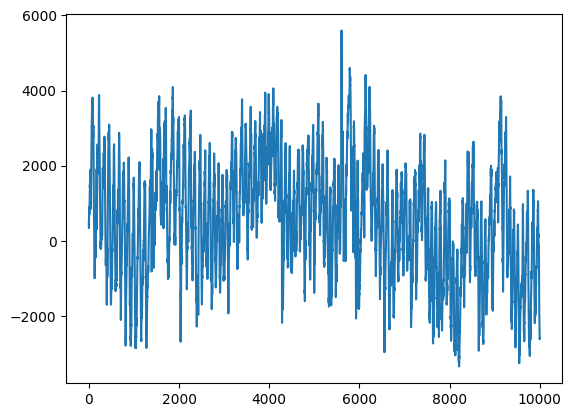

In [124]:
plt.plot(data.sniff[:10000])

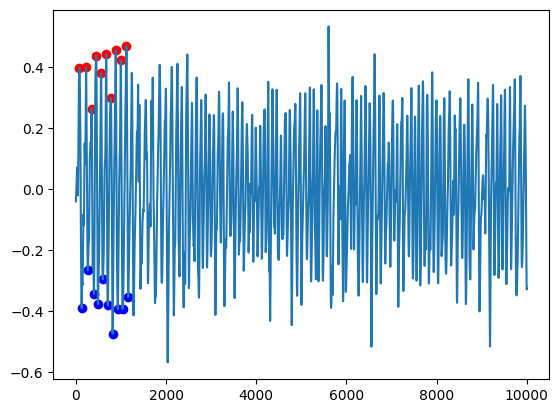

In [125]:
plt.plot(sniff[:10000])
plt.scatter(sniff_peaks[:10], sniff[sniff_peaks[:10]], color='red')
plt.scatter(sniff_troughs[:10], sniff[sniff_troughs[:10]], color='blue')

In [114]:
nose_y

[1091.67529296875,
 1099.6136474609375,
 1094.0150146484375,
 1088.4163818359375,
 1096.857666015625,
 1108.796142578125,
 1123.5201416015625,
 1132.666748046875,
 1147.99560546875,
 1155.495361328125,
 1160.410888671875,
 1175.877197265625,
 1211.671142578125,
 1224.1363525390625,
 1227.568115234375,
 1232.4171142578125,
 1228.219482421875,
 1223.8038330078125,
 1223.8660888671875,
 1215.318359375,
 1212.0318603515625,
 1219.3060302734375,
 1219.3067626953125,
 1211.677001953125,
 1212.2071236275335,
 1212.7372453019425,
 1213.2673669763512,
 1213.7974886507602,
 1214.327610325169,
 1214.8577319995777,
 1215.3878536739865,
 1215.9179753483952,
 1216.448097022804,
 1216.978218697213,
 1217.5083403716217,
 1218.0384620460304,
 1218.5685837204392,
 1219.098705394848,
 1219.6288270692569,
 1220.1589487436656,
 1220.6890704180744,
 1221.2191920924831,
 1221.749313766892,
 1222.2794354413006,
 1222.8095571157094,
 1223.3396787901183,
 1223.869800464527,
 1224.3999221389358,
 1224.9300438133

In [115]:
# Pxx_spec: power spectral density or power spectrum (depending on scaling)
f, Pxx_spec = signal.welch(theta, 1000, 'flattop', 1024, scaling='spectrum')

In [116]:
max(Pxx_spec)

np.float64(0.0035480224970694473)